# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Thời gian báo trước của cảnh báo bùng phát sốt xuất huyết trong năm dịch 2024 cho các đô thị Brazil đã thấy và chưa thấy, với số cảnh báo mỗi tuần có hạn

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [1]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `opendengue.org/data.html (Spatial extract, version 1.3)`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://raw.githubusercontent.com/OpenDengue/master-repo/main/data/releases/V1.3/Spatial_extract_V1_3.zip', 'Spatial_extract_V1_3.zip')]
NEED = ['Spatial_extract_V1_3.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from opendengue.org/data.html (Spatial extract, version 1.3) into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

downloading https://raw.githubusercontent.com/OpenDengue/master-repo/main/data/releases/V1.3/Spatial_extract_V1_3.zip
Spatial_extract_V1_3.csv -> data/raw/Spatial_extract_V1_3.csv 490605 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [4]:
# Step 1b: OpenDengue V1.3 (Clarke et al., 2024): weekly dengue counts per municipality, Brazil part, 2014-2024, about 1.9 million rows
# download (one zip, 55 MB, no account): https://raw.githubusercontent.com/OpenDengue/master-repo/main/data/releases/V1.3/Spatial_extract_V1_3.zip
import pandas as pd, numpy as np, glob, duckdb
src = glob.glob('data/raw/**/Spatial_extract_V1_3.csv', recursive=True)[0]
con = duckdb.connect()                                   # the CSV is 500 MB, DuckDB filters it without loading everything
df = con.execute(f"""SELECT adm_1_name AS state, adm_2_name AS municipality, CAST(IBGE_code AS BIGINT) AS ibge,
                            CAST(calendar_start_date AS DATE) AS week_start, CAST(dengue_total AS DOUBLE) AS cases
                     FROM read_csv_auto('{src}', nullstr='NA')
                     WHERE adm_0_name = 'BRAZIL' AND S_res = 'Admin2' AND T_res = 'Week' AND IBGE_code IS NOT NULL""").df()
df['week_start'] = pd.to_datetime(df.week_start); df['year'] = df.week_start.dt.year
print(df.shape, df.ibge.nunique(), 'municipalities', df.state.nunique(), 'states', df.week_start.min().date(), df.week_start.max().date())
print(df.groupby('year').agg(rows=('cases', 'size'), cases=('cases', 'sum'), municipalities=('ibge', 'nunique')))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(1895538, 6) 5517 municipalities 27 states 2013-12-29 2024-12-22
        rows      cases  municipalities
year                                   
2013    3690     4633.0            3690
2014  191880   588928.0            3690
2015  226772  1695323.0            4361
2016  236392  1514685.0            4546
2017  172892   246567.0            3906
2018  165699   271548.0            4535
2019  225161  1557769.0            4740
2020  211952   943380.0            4076
2021  196248   546113.0            3774
2022   76855  1393877.0            4604
2023   76816  1558692.0            4566
2024  111181  6392083.0            5214


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: balanced weekly panel for the municipalities with most cases; weeks absent from the source are set to zero and counted
log = [['raw municipality-weeks', len(df)], ['municipalities', df.ibge.nunique()]]
df = df.dropna(subset=['cases']).drop_duplicates(['ibge', 'week_start']); log.append(['unique municipality-week with a count', len(df)])
N_MUNI = 400                                             # chosen on years up to 2021 only, so the test year does not influence the choice
top = df[df.year <= 2021].groupby('ibge').cases.sum().nlargest(N_MUNI).index
weeks = pd.date_range(df.week_start.min(), df.week_start.max(), freq='7D')
grid = pd.MultiIndex.from_product([top, weeks], names=['ibge', 'week_start']).to_frame(index=False)
names = df.drop_duplicates('ibge')[['ibge', 'state', 'municipality']]
panel = grid.merge(df[['ibge', 'week_start', 'cases']], how='left').merge(names, on='ibge')
panel['filled'] = panel.cases.isna().astype(int); panel['cases'] = panel.cases.fillna(0)     # the source stores no zero rows after 2021
panel['year'] = panel.week_start.dt.year; panel['woy'] = panel.week_start.dt.isocalendar().week.astype(int)
log += [['municipalities kept', N_MUNI], ['panel rows', len(panel)], ['weeks filled with zero', int(panel.filled.sum())],
        ['weeks filled with zero in 2022-2024', int(panel.filled[panel.year >= 2022].sum())]]
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
panel.to_parquet('data/processed/dengue.parquet', index=False); print(panel.shape)

[['raw municipality-weeks', 1895538], ['municipalities', 5517], ['unique municipality-week with a count', 1895538], ['municipalities kept', 400], ['panel rows', 229600], ['weeks filled with zero', 15569], ['weeks filled with zero in 2022-2024', 14211]]
(229600, 8)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [6]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/dengue.parquet'); TGT, GRP = 'cases', 'state'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

229600 rows, 8 columns; 5 numeric columns; target: cases ; group: state


,ibge,week_start,cases,state,municipality,filled,year,woy
0,3106200,2013-12-29,31.0,MINAS GERAIS,BELO HORIZONTE,0,2013,52
1,3106200,2014-01-05,61.0,MINAS GERAIS,BELO HORIZONTE,0,2014,1
2,3106200,2014-01-12,44.0,MINAS GERAIS,BELO HORIZONTE,0,2014,2
3,3106200,2014-01-19,52.0,MINAS GERAIS,BELO HORIZONTE,0,2014,3
4,3106200,2014-01-26,78.0,MINAS GERAIS,BELO HORIZONTE,0,2014,4


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
ibge,int64,0.0,400,3106200
week_start,datetime64[ns],0.0,574,2013-12-29 00:00:00
cases,float64,0.0,2163,31.0
state,object,0.0,26,MINAS GERAIS
municipality,object,0.0,399,BELO HORIZONTE
filled,int64,0.0,2,0
year,int32,0.0,12,2013
woy,int64,0.0,53,52


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
ibge,50000.0,3473807.110,855976.787,1100205.0,1200609.0,3115300.0,3505500.0,3551702.0,5220405.00,5300108.0,0.448,0.0
cases,50000.0,50.891,505.288,0.0,0.0,0.0,3.0,15.0,767.01,54582.0,61.221,29.7
filled,50000.0,0.068,0.251,0.0,0.0,0.0,0.0,0.0,1.00,1.0,3.443,93.2
year,50000.0,2018.984,3.168,2013.0,2014.0,2016.0,2019.0,2022.0,2024.00,2024.0,0.000,0.0
woy,50000.0,26.650,15.118,1.0,1.0,14.0,27.0,40.0,52.00,53.0,-0.001,0.0


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 50000 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

{'count': 50000.0, 'mean': 50.891, 'std': 505.288, 'min': 0.0, '5%': 0.0, '50%': 3.0, '95%': 172.0, 'max': 54582.0}


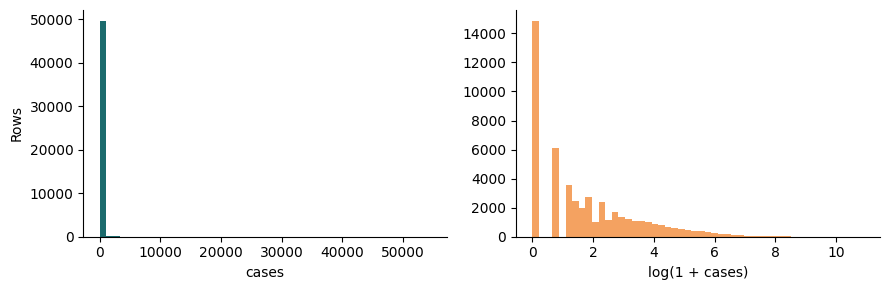

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color='#1B6B6D'); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#1B6B6D'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#F4A261'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

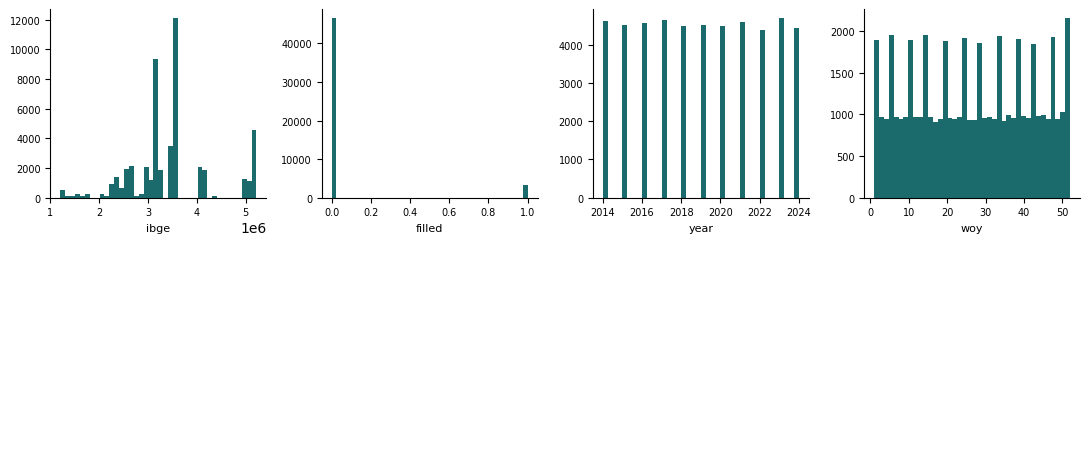

In [11]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#1B6B6D'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [12]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
ibge,23.69
cases,15.29
filled,6.76
year,0.00
woy,0.00


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
filled,-0.333
woy,-0.266
year,0.092
ibge,0.020


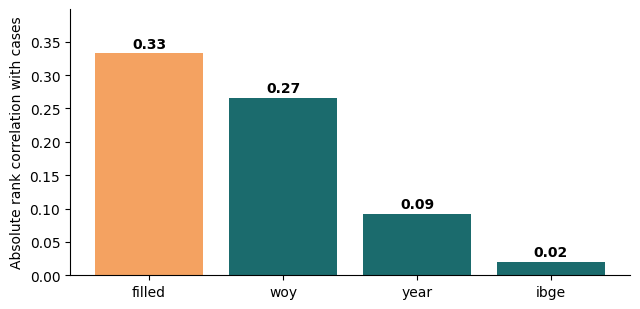

In [13]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

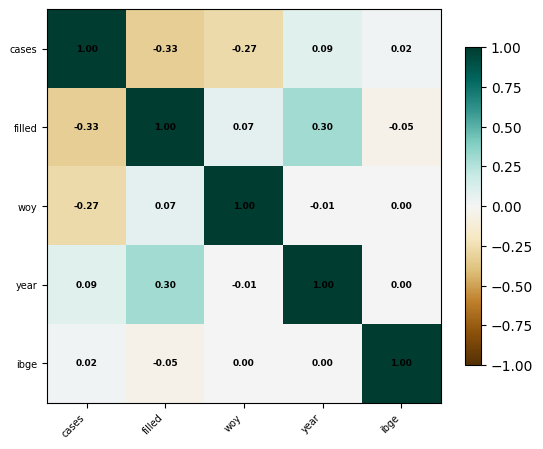

In [14]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap='BrBG', vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
state,,,,
SAO PAULO,70602,55.091,2.0,648.626
MINAS GERAIS,42476,56.621,2.0,451.634
GOIAS,20664,56.247,6.0,218.868
PARANA,17220,42.705,1.0,216.466
PERNAMBUCO,12054,20.323,3.0,77.382
BAHIA,10906,26.598,3.0,115.997
RIO DE JANEIRO,8610,52.241,3.0,345.475
CEARA,6888,29.407,2.0,133.754
MATO GROSSO DO SUL,5740,35.447,3.0,154.529


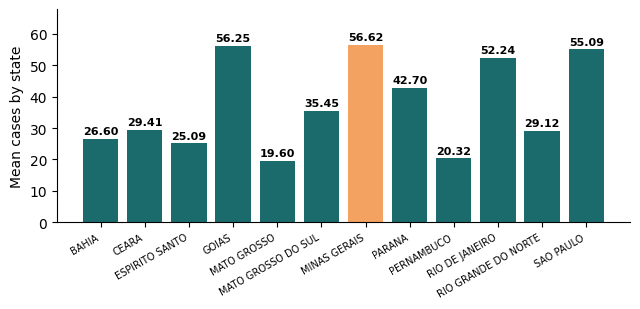

In [15]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [16]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE dg AS SELECT * FROM 'data/processed/dengue.parquet';
-- Q1: cases per year and the change against the previous year (LAG)
SELECT year, SUM(cases) AS cases, SUM(cases) / LAG(SUM(cases)) OVER (ORDER BY year) AS ratio_to_previous_year, SUM(filled) AS weeks_filled_zero
FROM dg GROUP BY 1 ORDER BY 1;
-- Q2: seasonality, share of yearly cases by month
SELECT MONTH(week_start) AS month, 100.0 * SUM(cases) / SUM(SUM(cases)) OVER () AS pct_of_cases FROM dg WHERE year BETWEEN 2015 AND 2023 GROUP BY 1 ORDER BY 1;
-- Q3: states in the 2024 epidemic against their own 2015-2023 mean, ranked
SELECT state, SUM(CASE WHEN year = 2024 THEN cases END) AS cases_2024, SUM(CASE WHEN year BETWEEN 2015 AND 2023 THEN cases END) / 9 AS mean_2015_2023,
       RANK() OVER (ORDER BY SUM(CASE WHEN year = 2024 THEN cases END) / NULLIF(SUM(CASE WHEN year BETWEEN 2015 AND 2023 THEN cases END) / 9, 0) DESC) AS rank_by_ratio
FROM dg GROUP BY 1 ORDER BY 4 LIMIT 15;
-- Q4: model table; outbreak = weekly cases above the municipality's own 75th percentile of the years up to 2022 (at least 5 cases);
-- features use the current and earlier weeks only, targets y1..y8 look 1 to 8 weeks ahead (LEAD)
CREATE OR REPLACE TABLE feat AS
WITH thr AS (SELECT ibge, GREATEST(QUANTILE_CONT(cases, 0.75), 5) AS thr FROM dg WHERE year <= 2022 GROUP BY 1),
st AS (SELECT state, week_start, AVG(LN(1 + cases)) AS state_log FROM dg GROUP BY 1, 2),
b AS (SELECT d.ibge, d.state, d.week_start, d.year, d.woy, d.filled, t.thr, LN(1 + t.thr) AS thr_log, LN(1 + d.cases) AS l0,
             CASE WHEN d.cases > t.thr THEN 1 ELSE 0 END AS above_now, s.state_log,
             LN(1 + LAG(d.cases, 1) OVER w) AS l1, LN(1 + LAG(d.cases, 2) OVER w) AS l2, LN(1 + LAG(d.cases, 3) OVER w) AS l3, LN(1 + LAG(d.cases, 52) OVER w) AS l52,
             AVG(LN(1 + d.cases)) OVER (PARTITION BY d.ibge ORDER BY d.week_start ROWS BETWEEN 3 PRECEDING AND CURRENT ROW) AS mean4,
             SIN(2 * PI() * d.woy / 52) AS woy_sin, COS(2 * PI() * d.woy / 52) AS woy_cos,
             LEAD(d.cases, 1) OVER w AS c1, LEAD(d.cases, 2) OVER w AS c2, LEAD(d.cases, 3) OVER w AS c3, LEAD(d.cases, 4) OVER w AS c4,
             LEAD(d.cases, 5) OVER w AS c5, LEAD(d.cases, 6) OVER w AS c6, LEAD(d.cases, 7) OVER w AS c7, LEAD(d.cases, 8) OVER w AS c8
      FROM dg d JOIN thr t USING (ibge) JOIN st s USING (state, week_start) WINDOW w AS (PARTITION BY d.ibge ORDER BY d.week_start))
SELECT ibge, state, week_start, year, woy, filled, thr, thr_log, l0, l1, l2, l3, l52, mean4, l0 - l1 AS growth, state_log, woy_sin, woy_cos, above_now,
       CAST(c1 > thr AS INT) AS y1, CAST(c2 > thr AS INT) AS y2, CAST(c3 > thr AS INT) AS y3, CAST(c4 > thr AS INT) AS y4,
       CAST(c5 > thr AS INT) AS y5, CAST(c6 > thr AS INT) AS y6, CAST(c7 > thr AS INT) AS y7, CAST(c8 > thr AS INT) AS y8
FROM b WHERE l52 IS NOT NULL AND c8 IS NOT NULL;
SELECT year, COUNT(*) AS rows, 100.0 * AVG(y4) AS outbreak_pct_4_weeks_ahead FROM feat GROUP BY 1 ORDER BY 1;
"""
open('sql/queries.sql', 'w').write(SQL)

3022

In [17]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [18]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE dg AS SELECT * FROM 'data/processed/dengue.parquet';""")

done


### Q1: cases per year and the change against the previous year (LAG)

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,year,cases,ratio_to_previous_year,weeks_filled_zero
0,2013,3202.0,NaN,2.0
1,2014,471428.0,147.229232,104.0
2,2015,1287733.0,2.731558,52.0
3,2016,1150849.0,0.893702,52.0
4,2017,182798.0,0.158838,262.0
5,2018,200643.0,1.097621,102.0
6,2019,1212650.0,6.043819,4.0
7,2020,623446.0,0.514119,208.0
8,2021,368596.0,0.591224,572.0
9,2022,788494.0,2.139182,5917.0


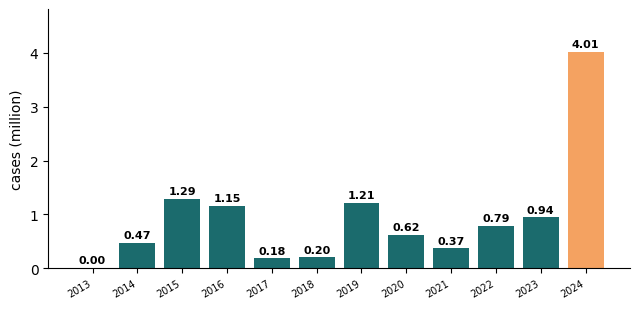

In [19]:
r = run(r"""-- Q1: cases per year and the change against the previous year (LAG)
SELECT year, SUM(cases) AS cases, SUM(cases) / LAG(SUM(cases)) OVER (ORDER BY year) AS ratio_to_previous_year, SUM(filled) AS weeks_filled_zero
FROM dg GROUP BY 1 ORDER BY 1;""")

### Q2: seasonality, share of yearly cases by month

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,month,pct_of_cases
0,1,8.134161
1,2,13.521533
2,3,20.968568
3,4,22.021646
4,5,15.676272
5,6,6.002610
6,7,2.843730
7,8,1.747515
8,9,1.404411
9,10,1.511917


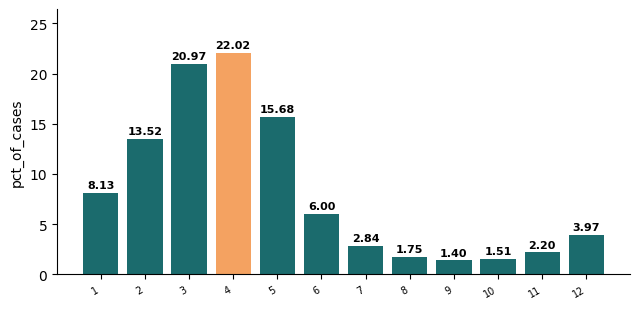

In [20]:
r = run(r"""-- Q2: seasonality, share of yearly cases by month
SELECT MONTH(week_start) AS month, 100.0 * SUM(cases) / SUM(SUM(cases)) OVER () AS pct_of_cases FROM dg WHERE year BETWEEN 2015 AND 2023 GROUP BY 1 ORDER BY 1;""")

### Q3: states in the 2024 epidemic against their own 2015-2023 mean, ranked

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,state,cases_2024,mean_2015_2023,rank_by_ratio
0,AMAPA,5771.0,514.444444,1
1,SANTA CATARINA,124472.0,11403.333333,2
2,DISTRITO FEDERAL,270827.0,29895.222222,3
3,RIO DE JANEIRO,215931.0,25284.444444,4
4,SAO PAULO,1753688.0,214210.000000,5
5,MINAS GERAIS,967403.0,154907.333333,6
6,RIO GRANDE DO SUL,3376.0,720.777778,7
7,PARANA,227000.0,55040.444444,8
8,BAHIA,81397.0,22239.444444,9
9,PARA,4229.0,1179.777778,10


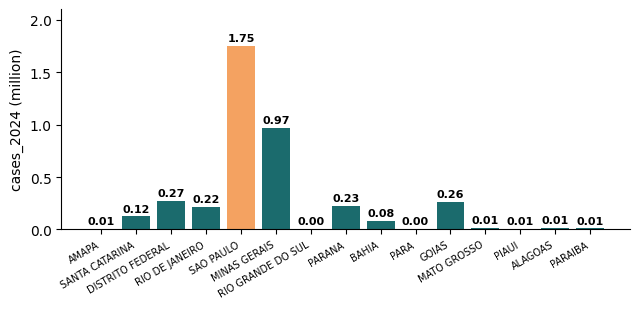

In [21]:
r = run(r"""-- Q3: states in the 2024 epidemic against their own 2015-2023 mean, ranked
SELECT state, SUM(CASE WHEN year = 2024 THEN cases END) AS cases_2024, SUM(CASE WHEN year BETWEEN 2015 AND 2023 THEN cases END) / 9 AS mean_2015_2023,
       RANK() OVER (ORDER BY SUM(CASE WHEN year = 2024 THEN cases END) / NULLIF(SUM(CASE WHEN year BETWEEN 2015 AND 2023 THEN cases END) / 9, 0) DESC) AS rank_by_ratio
FROM dg GROUP BY 1 ORDER BY 4 LIMIT 15;""")

### Q4: model table; outbreak = weekly cases above the municipality's own 75th percentile of the years up to 2022 (at least 5 cases);

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [22]:
r = run(r"""-- Q4: model table; outbreak = weekly cases above the municipality's own 75th percentile of the years up to 2022 (at least 5 cases);
-- features use the current and earlier weeks only, targets y1..y8 look 1 to 8 weeks ahead (LEAD)
CREATE OR REPLACE TABLE feat AS
WITH thr AS (SELECT ibge, GREATEST(QUANTILE_CONT(cases, 0.75), 5) AS thr FROM dg WHERE year <= 2022 GROUP BY 1),
st AS (SELECT state, week_start, AVG(LN(1 + cases)) AS state_log FROM dg GROUP BY 1, 2),
b AS (SELECT d.ibge, d.state, d.week_start, d.year, d.woy, d.filled, t.thr, LN(1 + t.thr) AS thr_log, LN(1 + d.cases) AS l0,
             CASE WHEN d.cases > t.thr THEN 1 ELSE 0 END AS above_now, s.state_log,
             LN(1 + LAG(d.cases, 1) OVER w) AS l1, LN(1 + LAG(d.cases, 2) OVER w) AS l2, LN(1 + LAG(d.cases, 3) OVER w) AS l3, LN(1 + LAG(d.cases, 52) OVER w) AS l52,
             AVG(LN(1 + d.cases)) OVER (PARTITION BY d.ibge ORDER BY d.week_start ROWS BETWEEN 3 PRECEDING AND CURRENT ROW) AS mean4,
             SIN(2 * PI() * d.woy / 52) AS woy_sin, COS(2 * PI() * d.woy / 52) AS woy_cos,
             LEAD(d.cases, 1) OVER w AS c1, LEAD(d.cases, 2) OVER w AS c2, LEAD(d.cases, 3) OVER w AS c3, LEAD(d.cases, 4) OVER w AS c4,
             LEAD(d.cases, 5) OVER w AS c5, LEAD(d.cases, 6) OVER w AS c6, LEAD(d.cases, 7) OVER w AS c7, LEAD(d.cases, 8) OVER w AS c8
      FROM dg d JOIN thr t USING (ibge) JOIN st s USING (state, week_start) WINDOW w AS (PARTITION BY d.ibge ORDER BY d.week_start))
SELECT ibge, state, week_start, year, woy, filled, thr, thr_log, l0, l1, l2, l3, l52, mean4, l0 - l1 AS growth, state_log, woy_sin, woy_cos, above_now,
       CAST(c1 > thr AS INT) AS y1, CAST(c2 > thr AS INT) AS y2, CAST(c3 > thr AS INT) AS y3, CAST(c4 > thr AS INT) AS y4,
       CAST(c5 > thr AS INT) AS y5, CAST(c6 > thr AS INT) AS y6, CAST(c7 > thr AS INT) AS y7, CAST(c8 > thr AS INT) AS y8
FROM b WHERE l52 IS NOT NULL AND c8 IS NOT NULL;""")

done


### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,year,rows,outbreak_pct_4_weeks_ahead
0,2014,400,34.750000
1,2015,20800,42.250000
2,2016,20800,26.163462
3,2017,21200,6.080189
4,2018,20800,8.485577
5,2019,20800,36.591346
6,2020,20800,22.572115
7,2021,20800,13.610577
8,2022,20800,25.504808
9,2023,21200,33.660377


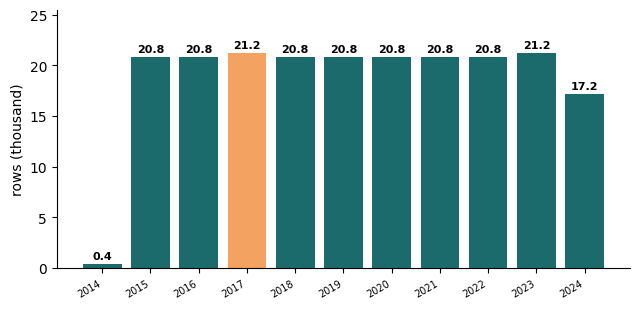

In [23]:
r = run(r"""SELECT year, COUNT(*) AS rows, 100.0 * AVG(y4) AS outbreak_pct_4_weeks_ahead FROM feat GROUP BY 1 ORDER BY 1;""")

### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,column_name,column_type,min,max,approx_unique,null_percentage
0,ibge,BIGINT,1100205,5300108,484,0.0
1,week_start,TIMESTAMP_NS,2013-12-29 00:00:00,2024-12-22 00:00:00,625,0.0
2,cases,DOUBLE,0.0,54582.0,2485,0.0
3,state,VARCHAR,ACRE,TOCANTINS,24,0.0
4,municipality,VARCHAR,ADAMANTINA,VOTUPORANGA,394,0.0
5,filled,BIGINT,0,1,2,0.0
6,year,INTEGER,2013,2024,13,0.0
7,woy,BIGINT,1,53,47,0.0


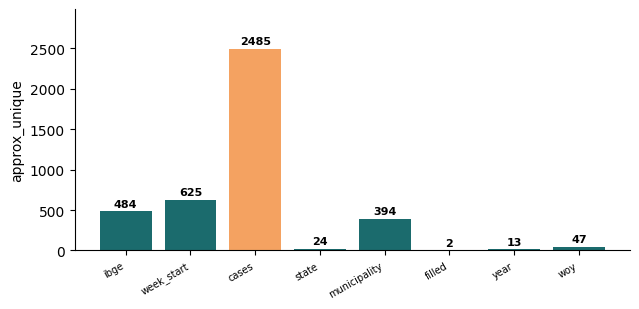

In [24]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE dg)''')

### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [25]:
r = run('''SELECT COUNT(*) AS n, MIN("cases") AS min, QUANTILE_CONT("cases", 0.05) AS p05, QUANTILE_CONT("cases", 0.25) AS p25, MEDIAN("cases") AS p50, QUANTILE_CONT("cases", 0.75) AS p75, QUANTILE_CONT("cases", 0.95) AS p95, QUANTILE_CONT("cases", 0.99) AS p99, MAX("cases") AS max FROM dg''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,229600,0.0,0.0,0.0,3.0,16.0,170.0,761.0,54582.0


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,DISTRITO FEDERAL,964.297909,574,0.25,1
1,SANTA CATARINA,197.842334,1148,0.50,2
2,PIAUI,94.360627,574,0.25,3
3,MINAS GERAIS,56.620751,42476,18.50,4
4,GOIAS,56.247193,20664,9.00,5
5,SAO PAULO,55.091031,70602,30.75,6
6,RIO DE JANEIRO,52.240999,8610,3.75,7
7,PARANA,42.704820,17220,7.50,8
8,AMAZONAS,41.635889,574,0.25,9
9,ACRE,40.603368,1722,0.75,10


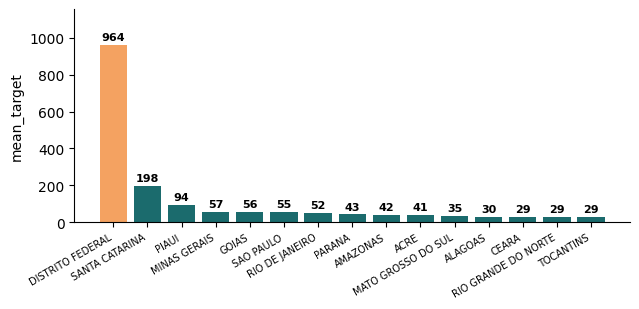

In [26]:
r = run('''SELECT CAST("state" AS VARCHAR) AS grp, AVG("cases") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("cases") DESC) AS rank_by_mean FROM dg GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [27]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

,column_name,column_type,null_percentage,approx_unique
0,ibge,BIGINT,0.0,484
1,state,VARCHAR,0.0,24
2,week_start,TIMESTAMP_NS,0.0,574
3,year,INTEGER,0.0,12
4,woy,BIGINT,0.0,47
5,filled,BIGINT,0.0,2
6,thr,DOUBLE,0.0,98
7,thr_log,DOUBLE,0.0,80
8,l0,DOUBLE,0.0,2040
9,l1,DOUBLE,0.0,2040


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

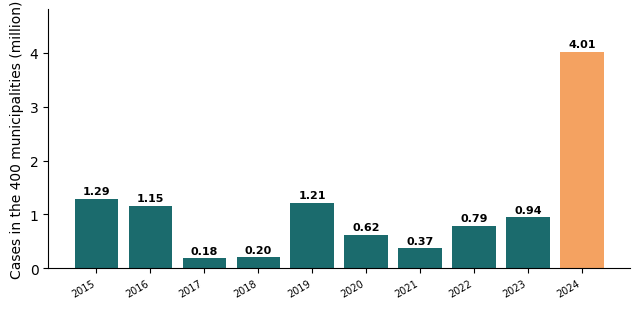

In [28]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT CAST(year AS VARCHAR) AS g, SUM(cases) / 1e6 AS v FROM dg WHERE year >= 2015 GROUP BY year ORDER BY year""").df()
bar_chart(fig1.g, fig1.v, 'Cases in the 400 municipalities (million)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [29]:
import json, hashlib
path = 'data/processed/dengue.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/dengue.parquet', 'rows': 229600, 'columns': 8, 'feat_rows': 205600, 'md5': '99ebac66cc750c770a8428622f41d378'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: